**Import Library**

In [ ]:
!pip install PySastrawi -q

In [ ]:
import os
import re
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from collections import defaultdict

# Sastrawi
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory

# Scikit-learn
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.tree import plot_tree
from sklearn.pipeline import Pipeline

from sklearn.naive_bayes import MultinomialNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.base import clone

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report, ConfusionMatrixDisplay)
from sklearn.preprocessing import LabelEncoder

warnings.filterwarnings('ignore')

**Load Dataset**

In [ ]:
df = pd.read_csv('535240145_data.csv')

In [ ]:
# Menampilkan ukuran data
print("Ukuran dataset:", df.shape)
display(df.head())

Ukuran dataset: (4581, 8)


,title,source,date,time,category,sub-category,content,url
0,Ini Kekhawatiran Abraham Samad Bila Revisi UU ...,liputan6.com,2019-09-12,20:46,News,Peristiwa,Mantan pimpinan Komisi Pemberantasan Korupsi ...,https://www.liputan6.com/news/read/4061469/ini...
1,DPR Sahkan RUU Sumber Daya Air Jadi Undang-Undang,liputan6.com,2019-09-17,19:24,News,Politik,DPR mengesahkan Rancangan Undang-Undang Sumbe...,https://www.liputan6.com/news/read/4065047/dpr...
2,"Soal Revisi UU KPK, Sekjen PDIP: Kami Dukung J...",liputan6.com,2019-09-15,20:42,News,Politik,Sekretaris Jenderal PDI Perjuangan Hasto Kris...,https://www.liputan6.com/news/read/4063347/soa...
3,Golkar DKI Minta Anies Jadikan BJ Habibie Nama...,liputan6.com,2019-09-17,19:45,News,Peristiwa,Pelaksana Tugas (Plt) Ketua DPD Partai Golkar...,https://www.liputan6.com/news/read/4065065/gol...
4,"Kapolda Metro Apresiasi Bripka Eka, Minta Tak ...",liputan6.com,2019-09-17,19:48,News,Peristiwa,Kapolda Metro Jaya Irjen Gatot Eddy memberika...,https://www.liputan6.com/news/read/4065086/kap...


**Pemeriksaan Awal Dataset**

In [ ]:
# Info dataset
print("Info dataset:")
df.info()

Info dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4581 entries, 0 to 4580
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   title         4581 non-null   object
 1   source        4581 non-null   object
 2   date          4581 non-null   object
 3   time          4581 non-null   object
 4   category      4581 non-null   object
 5   sub-category  4581 non-null   object
 6   content       4574 non-null   object
 7   url           4581 non-null   object
dtypes: object(8)
memory usage: 286.4+ KB


In [ ]:
df.columns.tolist()

['title',
 'source',
 'date',
 'time',
 'category',
 'sub-category',
 'content',
 'url']

In [ ]:
df.content[0]

' Mantan pimpinan Komisi Pemberantasan Korupsi (KPK) Abraham Samad menyebut revisi Undang-Undang Nomor 30 Tahun 2002 tentang KPK yang diusulkan oleh DPR RI mengancam agenda pemberantasan korupsi. Menurutnya, KPK hendak dimasukkan sebagai lembaga penegak hukum, berada pada cabang kekuasaan eksekutif atau pemerintahan di bawah Presiden.,Poin yang dikhawatirkan Ketua KPK periode 2011-2015 ini adalah pasal mengenai penyelidik dan penyidik. Dalam draf revisi UU tersebut menyebutkan bahwa penyidik maupun penyelidik KPK harus berasal dari Kepolisian, Kejaksaan ataupun Pegawai Negeri Sipil (PNS) yang diangkat oleh pemerintah.,Dengan demikian, apa yang dilakukan KPK selama ini yaitu merekrut, mengangkat dan mensahkan penyelidik dan penyidik internalnya, termasuk yang telah memeriksa kasus-kasus korupsi dan selesai memeriksa kasus itu, dianggap tidak sah.,"Konsekuensinya kalau revisi UU KPK disetujui, semua koruptor yang tengah menjalani hukuman harus dikeluarkan dari tahanan pada saat itu juga.

In [ ]:
# Missing values
df.isna().sum().sort_values(ascending=False)

,0
content,7
title,0
date,0
source,0
time,0
category,0
sub-category,0
url,0


In [ ]:
# Duplikasi data
n_dup = df.duplicated().sum()
print(f'Jumlah baris duplikat: {n_dup}')

Jumlah baris duplikat: 0


**Visualisasi Awal Dataset**

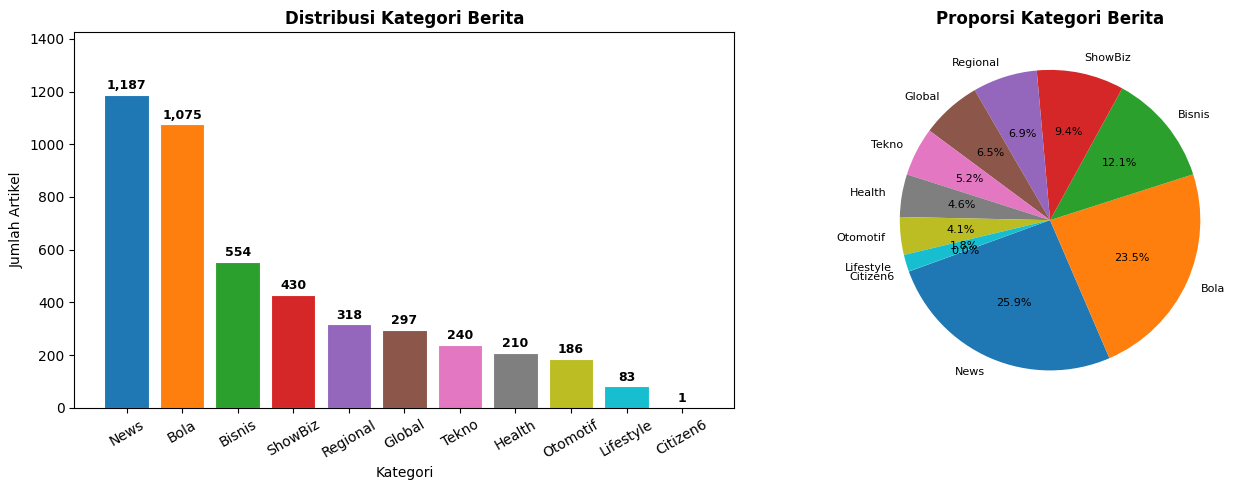

In [ ]:
# Distribusi Kategori Berita
cat_counts = df['category'].value_counts()
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

colors = plt.cm.tab10(np.linspace(0, 1, len(cat_counts)))
bars = axes[0].bar(cat_counts.index, cat_counts.values,
                   color=colors, edgecolor='white', linewidth=0.8)
for bar, val in zip(bars, cat_counts.values):
    axes[0].annotate(f'{val:,}',
                     xy=(bar.get_x() + bar.get_width()/2, bar.get_height()),
                     xytext=(0, 4), textcoords='offset points',
                     ha='center', fontsize=9, fontweight='bold')
axes[0].set_title('Distribusi Kategori Berita', fontweight='bold', fontsize=12)
axes[0].set_xlabel('Kategori', fontsize=10)
axes[0].set_ylabel('Jumlah Artikel', fontsize=10)
axes[0].tick_params(axis='x', rotation=30)
axes[0].set_ylim(0, max(cat_counts.values) * 1.2)

wedges, texts, autotexts = axes[1].pie(
    cat_counts.values, labels=cat_counts.index,
    colors=colors, autopct='%1.1f%%', startangle=200,
    textprops={'fontsize': 8})
axes[1].set_title('Proporsi Kategori Berita', fontweight='bold', fontsize=12)

plt.tight_layout()
plt.savefig('distribusi_kategori.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
print('Distribusi Kategori Berita:')
display(cat_counts.to_frame('Jumlah').assign(
    Persentase=lambda x: (x['Jumlah']/x['Jumlah'].sum()*100).round(2)))

Distribusi Kategori Berita:


,Jumlah,Persentase
category,,
News,1187,25.91
Bola,1075,23.47
Bisnis,554,12.09
ShowBiz,430,9.39
Regional,318,6.94
Global,297,6.48
Tekno,240,5.24
Health,210,4.58
Otomotif,186,4.06


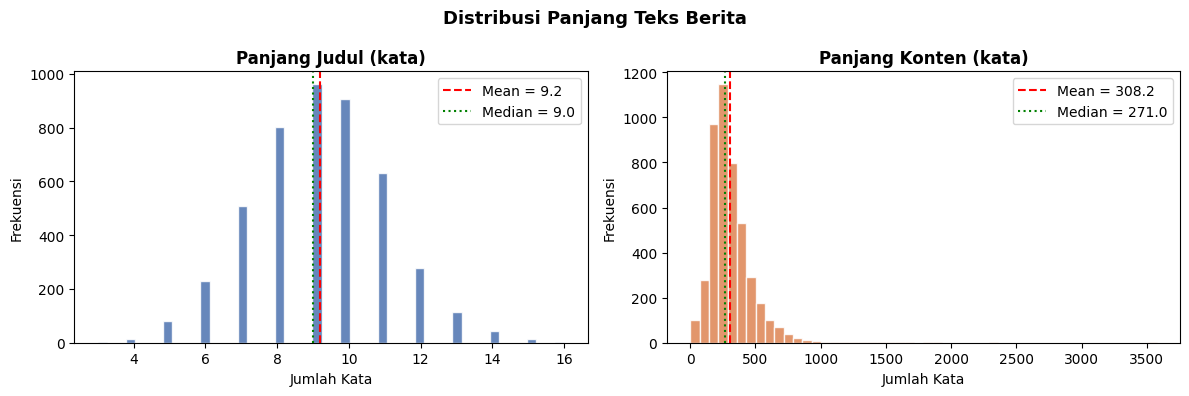

In [ ]:
# Distribusi Panjang Isi Berita
df['title_len'] = df['title'].apply(lambda x: len(str(x).split()))
df['content_len'] = df['content'].apply(lambda x: len(str(x).split()))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, col, label, color in zip(
        axes, ['title_len', 'content_len'],
        ['Panjang Judul (kata)', 'Panjang Konten (kata)'],
        ['#4C72B0', '#DD8452']):
    ax.hist(df[col], bins=50, color=color, edgecolor='white', alpha=0.85)
    ax.axvline(df[col].mean(), color='red', linestyle='--', lw=1.5,
               label=f'Mean = {df[col].mean():.1f}')
    ax.axvline(df[col].median(), color='green', linestyle=':', lw=1.5,
               label=f'Median = {df[col].median():.1f}')
    ax.set_title(label, fontweight='bold')
    ax.set_xlabel('Jumlah Kata')
    ax.set_ylabel('Frekuensi')
    ax.legend()

plt.suptitle('Distribusi Panjang Teks Berita', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('distribusi_juduldankonten.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
# Statistik Deskriptif
display(df[['title_len', 'content_len']].describe().round(2))

,title_len,content_len
count,4581.00,4581.00
mean,9.19,308.25
std,1.86,178.20
min,3.00,1.00
25%,8.00,205.00
50%,9.00,271.00
75%,10.00,375.00
max,16.00,3575.00


**Pembersihan Data**

In [ ]:
df_clean = df.dropna(subset=['content', 'title', 'category']).copy()
df_clean = df_clean[df_clean['content'].str.strip() != '']
df_clean = df_clean[df_clean['title'].str.strip() != '']
df_clean.drop_duplicates(inplace=True)
df_clean.reset_index(drop=True, inplace=True)

print(f'Setelah pembersihan data: {df_clean.shape[0]:,} baris')
print(f'Kategori unik: {df_clean["category"].nunique()}')
display(df_clean["category"].value_counts().to_frame('Jumlah'))

Setelah pembersihan data: 4,574 baris
Kategori unik: 11


,Jumlah
category,
News,1183
Bola,1075
Bisnis,553
ShowBiz,430
Regional,318
Global,297
Tekno,240
Health,209
Otomotif,186


In [ ]:
MIN_SAMPLES = 100
category_counts = df_clean['category'].value_counts()
valid_cats = category_counts[category_counts >= MIN_SAMPLES].index.tolist()
removed_cats = category_counts[category_counts < MIN_SAMPLES]

df_filtered = df_clean[df_clean['category'].isin(valid_cats)].copy()
df_filtered.reset_index(drop=True, inplace=True)

print(f'Kategori yang digunakan ({len(valid_cats)}):')
display(df_filtered['category'].value_counts())

print('\nKategori yang dibuang karena sampel terlalu sedikit:')
display(removed_cats.to_frame('Jumlah'))

print(f'\nTotal sampel: {len(df_filtered):,}')

Kategori yang digunakan (9):


,count
category,
News,1183
Bola,1075
Bisnis,553
ShowBiz,430
Regional,318
Global,297
Tekno,240
Health,209
Otomotif,186



Kategori yang dibuang karena sampel terlalu sedikit:


,Jumlah
category,
Lifestyle,82
Citizen6,1



Total sampel: 4,491


**Preprocessing Teks Bahasa Indonesia**

In [ ]:
stemmer_factory    = StemmerFactory()
stopword_factory   = StopWordRemoverFactory()
stemmer            = stemmer_factory.create_stemmer()
stopword_remover   = stopword_factory.create_stop_word_remover()
STOP_WORDS_ID      = set(stopword_factory.get_stop_words())

print(f'Stemmer    : Sastrawi')
print(f'Stopwords  : {len(STOP_WORDS_ID):,} kata')

Stemmer    : Sastrawi
Stopwords  : 809 kata


In [ ]:
print(STOP_WORDS_ID)

{'inikah', 'sesaat', 'dahulu', 'sekurangnya', 'memang', 'akankah', 'sekiranya', 'yakin', 'p', 'sendiri', 'agak', 'melihatnya', 'pak', 'ditunjuk', 'menunjuki', 'sebetulnya', 'telah', 'berupa', 'sama-sama', 'dirinya', 'arti', 'bisa', 'menyeluruh', 'akhirnya', 'berujar', 'biasanya', 'diantara', 'seusai', 'bermacam-macam', 'terutama', 'menunjuknya', 'siapapun', 'kepada', 'cukup', 'kapankah', 'diberikannya', 'terjadilah', 'sekitarnya', 'bagaikan', 'menyebutkan', 'terus', 'diungkapkan', 'teringat', 'nantinya', 'kamilah', 'selamanya', 'setidak-tidaknya', 'panjang', 'mempertanyakan', 'tersampaikan', 'mulai', 'setibanya', 'sewaktu', 'menantikan', 'semaunya', 'tampak', 'seorang', 'seolah-olah', 'berikutnya', 'tunjuk', 'ternyata', 'amatlah', 'dilihat', 'seperti', 'jangan', 'masing-masing', 'buat', 'usah', 'padanya', 'akulah', 'beberapa', 'kira-kira', 'sangat', 'setiba', 'lanjut', 'usai', 'tuturnya', 'tiap', 'perlunya', 'sudahlah', 'andalah', 'semacam', 'mampu', 'bersiap-siap', 'tetap', 'tadi', 'd

In [ ]:
# Fungsi preprocessing
def preprocess_text(text: str) -> str:
    if not isinstance(text, str) or text.strip() == '':
        return ''
    # Lowercase
    text = text.lower()
    # Hapus URL
    text = re.sub(r'https?://\S+|www\.\S+', ' ', text)
    # Hapus angka
    text = re.sub(r'\d+', ' ', text)
    # Hapus tanda baca dan karakter non-alfabet
    text = re.sub(r'[^a-z\s]', ' ', text)
    # Normalisasi spasi
    text = re.sub(r'\s+', ' ', text).strip()
    # Stopword removal
    text = stopword_remover.remove(text)
    # Stemming
    text = stemmer.stem(text)
    return text

In [ ]:
t0 = time.time()

df_filtered['text_combined'] = df_filtered['title'].fillna('') + ' ' + df_filtered['content'].fillna('')
df_filtered['text_clean']    = df_filtered['text_combined'].apply(preprocess_text)

elapsed = time.time() - t0
print(f'Preprocessing selama {elapsed:.1f} detik')

Preprocessing selama 25.5 detik


In [ ]:
df_filtered = df_filtered[df_filtered['text_clean'].str.strip() != ''].reset_index(drop=True)

print(f'Contoh hasil preprocessing:')
for i in range(2):
    print(f'\nSebelum: {df_filtered["title"].iloc[i][:100]}')
    print(f'Sesudah: {df_filtered["text_clean"].iloc[i][:100]}')

display(df_filtered[["title", "text_clean", "category"]].head(3))

Contoh hasil preprocessing:

Sebelum: Ini Kekhawatiran Abraham Samad Bila Revisi UU KPK Dibahas DPR-Pemerintah
Sesudah: khawatir abraham samad revisi uu kpk bahas dpr perintah mantan pimpin komisi berantas korupsi kpk ab

Sebelum: DPR Sahkan RUU Sumber Daya Air Jadi Undang-Undang
Sesudah: dpr sahkan ruu sumber daya air undang undang dpr kesah rancang undang undang sumber daya air ruu sda


,title,text_clean,category
0,Ini Kekhawatiran Abraham Samad Bila Revisi UU ...,khawatir abraham samad revisi uu kpk bahas dpr...,News
1,DPR Sahkan RUU Sumber Daya Air Jadi Undang-Undang,dpr sahkan ruu sumber daya air undang undang d...,News
2,"Soal Revisi UU KPK, Sekjen PDIP: Kami Dukung J...",revisi uu kpk sekjen pdip dukung jokowi sepenu...,News


In [ ]:
TEXT_COL  = 'text_clean'
LABEL_COL = 'category'

print(f'Kolom teks  : {TEXT_COL}')
print(f'Kolom label : {LABEL_COL}')

Kolom teks  : text_clean
Kolom label : category


In [ ]:
print(f'Kolom "{TEXT_COL}" adalah hasil preprocessing teks berita'
      f' dan "{LABEL_COL}" adalah kategori berita yang akan diprediksi.')

Kolom "text_clean" adalah hasil preprocessing teks berita dan "category" adalah kategori berita yang akan diprediksi.


In [ ]:
le = LabelEncoder()
y  = le.fit_transform(df_filtered[LABEL_COL])
X_raw = df_filtered[TEXT_COL].values

CLASS_NAMES = le.classes_
N_CLASSES   = len(CLASS_NAMES)

In [ ]:
# Ukuran data
print(f'Ukuran X : {X_raw.shape}')
print(f'Ukuran y : {y.shape}')

Ukuran X : (4491,)
Ukuran y : (4491,)


In [ ]:
print(f'Jumlah kelas : {len(df_filtered)}')
print(f'Jumlah kelas : {N_CLASSES}')
print(f'Kelas        : {CLASS_NAMES.tolist()}')

Jumlah kelas : 4491
Jumlah kelas : 9
Kelas        : ['Bisnis', 'Bola', 'Global', 'Health', 'News', 'Otomotif', 'Regional', 'ShowBiz', 'Tekno']


In [ ]:
print(f'Distribusi kelas:')
unique, counts = np.unique(y, return_counts=True)
for cls_id, cnt in zip(unique, counts):
    print(f'[{cls_id}] {CLASS_NAMES[cls_id]:<12}: {cnt:,} ({cnt/len(y)*100:.1f}%)')

Distribusi kelas:
[0] Bisnis      : 553 (12.3%)
[1] Bola        : 1,075 (23.9%)
[2] Global      : 297 (6.6%)
[3] Health      : 209 (4.7%)
[4] News        : 1,183 (26.3%)
[5] Otomotif    : 186 (4.1%)
[6] Regional    : 318 (7.1%)
[7] ShowBiz     : 430 (9.6%)
[8] Tekno       : 240 (5.3%)


**Model dan Evaluasi**

In [ ]:
# K-Fold | k = 5
K_FOLDS    = 5
RANDOM_STATE = 42

skf = StratifiedKFold(n_splits=K_FOLDS, shuffle=True, random_state=RANDOM_STATE)

print(f'Stratified K-Fold dengan k = {K_FOLDS}, random_state = {RANDOM_STATE}')
print(f'Setiap fold berisi ± {len(y)//K_FOLDS:,} sampel uji')

print('\nDistribusi kelas per fold (training):')
for fold_i, (train_idx, test_idx) in enumerate(skf.split(X_raw, y), 1):
    unique_tr, cnt_tr = np.unique(y[train_idx], return_counts=True)
    print(f'Fold {fold_i} | Train = {len(train_idx):,}  Test = {len(test_idx):,} | '
          + '  '.join([f'{CLASS_NAMES[c]} : {cnt}' for c, cnt in zip(unique_tr, cnt_tr)]))

Stratified K-Fold dengan k = 5, random_state = 42
Setiap fold berisi ± 898 sampel uji

Distribusi kelas per fold (training):
Fold 1 | Train = 3,592  Test = 899 | Bisnis : 442  Bola : 860  Global : 238  Health : 167  News : 946  Otomotif : 149  Regional : 254  ShowBiz : 344  Tekno : 192
Fold 2 | Train = 3,593  Test = 898 | Bisnis : 443  Bola : 860  Global : 237  Health : 168  News : 946  Otomotif : 148  Regional : 255  ShowBiz : 344  Tekno : 192
Fold 3 | Train = 3,593  Test = 898 | Bisnis : 443  Bola : 860  Global : 237  Health : 167  News : 946  Otomotif : 149  Regional : 255  ShowBiz : 344  Tekno : 192
Fold 4 | Train = 3,593  Test = 898 | Bisnis : 442  Bola : 860  Global : 238  Health : 167  News : 947  Otomotif : 149  Regional : 254  ShowBiz : 344  Tekno : 192
Fold 5 | Train = 3,593  Test = 898 | Bisnis : 442  Bola : 860  Global : 238  Health : 167  News : 947  Otomotif : 149  Regional : 254  ShowBiz : 344  Tekno : 192


In [ ]:
# TF-IDF
TFIDF_PARAMS = dict(
    max_features=10000,
    ngram_range=(1, 2),
    min_df=2,
    sublinear_tf=True
)

# Multinomial Naive Bayes
nb_model = MultinomialNB(alpha=1.0)

# Decision Tree
dt_model = DecisionTreeClassifier(
    criterion='entropy',
    max_depth=None,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=RANDOM_STATE
)

# AdaBoost
ada_base = DecisionTreeClassifier(
    criterion='entropy',
    max_depth=3,
    random_state=RANDOM_STATE
)
ada_model = AdaBoostClassifier(
    estimator=ada_base,
    n_estimators=100,
    learning_rate=1.0,
    algorithm='SAMME',
    random_state=RANDOM_STATE
)

# Pipeline
def make_pipeline(clf):
    return Pipeline([
        ('tfidf', TfidfVectorizer(**TFIDF_PARAMS)),
        ('clf',   clone(clf))
    ])

MODELS = {
    'Naive Bayes':   nb_model,
    'Decision Tree': dt_model,
    'AdaBoost':      ada_model
}

MODEL_COLORS = {
    'Naive Bayes':   '#4C72B0',
    'Decision Tree': '#DD8452',
    'AdaBoost':      '#55A868'
}

In [ ]:
# Fungsi Evaluasi dan Visualisasi
def extract_tpfpfntn_per_class(cm: np.ndarray, class_names: list) -> pd.DataFrame:
    rows = []
    n = cm.shape[0]
    for i in range(n):
        tp = cm[i, i]
        fp = cm[:, i].sum() - tp
        fn = cm[i, :].sum() - tp
        tn = cm.sum() - tp - fp - fn
        rows.append({'Kelas': class_names[i], 'TP': tp, 'FP': fp, 'FN': fn, 'TN': tn})
    return pd.DataFrame(rows)

def run_kfold_experiment(base_clf, model_name: str, X_raw, y, class_names, skf, tfidf_params):
    fold_results  = []
    fold_cms      = []
    fold_reports  = []

    print(f'{model_name}')

    for fold_i, (train_idx, test_idx) in enumerate(skf.split(X_raw, y), 1):
        X_train_raw = X_raw[train_idx]
        X_test_raw  = X_raw[test_idx]
        y_train     = y[train_idx]
        y_test      = y[test_idx]

        pipeline = Pipeline([
            ('tfidf', TfidfVectorizer(**tfidf_params)),
            ('clf',   clone(base_clf))
        ])

        t0 = time.time()
        pipeline.fit(X_train_raw, y_train)
        t_fit = time.time() - t0

        y_pred = pipeline.predict(X_test_raw)

        acc   = accuracy_score(y_test, y_pred)
        prec  = precision_score(y_test, y_pred, average='weighted', zero_division=0)
        rec   = recall_score(y_test, y_pred, average='weighted', zero_division=0)
        f1    = f1_score(y_test, y_pred, average='weighted', zero_division=0)
        cm    = confusion_matrix(y_test, y_pred, labels=list(range(len(class_names))))
        report = classification_report(y_test, y_pred,
                                        target_names=class_names,
                                        digits=4, zero_division=0)

        fold_results.append({
            'fold': fold_i, 'accuracy': acc, 'precision': prec,
            'recall': rec, 'f1_score': f1, 'time_sec': t_fit
        })
        fold_cms.append(cm)
        fold_reports.append(report)

        print(f'Fold {fold_i} / {K_FOLDS}: '
              f'Accuracy = {acc:.4f}  Precision = {prec:.4f}  Recall = {rec:.4f}  F1-Score = {f1:.4f}  '
              f'Waktu = {t_fit:.2f}s')

    return fold_results, fold_cms, fold_reports

def print_fold_table(fold_results: list, model_name: str) -> pd.DataFrame:
    df_res = pd.DataFrame(fold_results)
    print(f'\n{model_name}')

    avg = df_res[['accuracy','precision','recall','f1_score','time_sec']].mean().to_frame().T
    avg['fold'] = 'Rata-rata'

    std = df_res[['accuracy','precision','recall','f1_score','time_sec']].std().to_frame().T
    std['fold'] = 'Std Dev'

    display_df = pd.concat([df_res, avg, std], ignore_index=True)
    display(display_df.round(4))

    return df_res

def plot_cm_per_fold(fold_cms: list, class_names: list, model_name: str, cmap: str = 'Blues'):
    n = len(fold_cms)
    fig, axes = plt.subplots(1, n, figsize=(n * 3.5, 3.5))
    if n == 1:
        axes = [axes]
    for i, (cm, ax) in enumerate(zip(fold_cms, axes)):
        disp = ConfusionMatrixDisplay(
            confusion_matrix=cm,
            display_labels=class_names
        )
        disp.plot(values_format='d', cmap=cmap, ax=ax, colorbar=False)
        ax.set_title(f'Fold {i+1}', fontweight='bold', fontsize=9)
        ax.set_xlabel('Prediksi', fontsize=7)
        ax.set_ylabel('Aktual', fontsize=7)
        ax.tick_params(axis='both', labelsize=6)
    fig.suptitle(f'Confusion Matrix Tiap Fold — {model_name}',
                 fontweight='bold', fontsize=11, y=1.02)
    plt.tight_layout()
    fname = f'cm_fold_{model_name.lower().replace(" ","_")}.png'
    plt.savefig(fname, dpi=150, bbox_inches='tight')
    plt.show()

def aggregate_cm(fold_cms: list) -> np.ndarray:
    return np.sum(fold_cms, axis=0)

In [ ]:
print('Konfigurasi Pipeline (TF-IDF + Model):')
for name, mdl in MODELS.items():
    print(f'{name}')
    print(f'TF-IDF: max_features={TFIDF_PARAMS["max_features"]},',
          f'ngram_range={TFIDF_PARAMS["ngram_range"]},',
          f'min_df={TFIDF_PARAMS["min_df"]}, sublinear_tf={TFIDF_PARAMS["sublinear_tf"]}')
    print(f'{mdl}:')

Konfigurasi Pipeline (TF-IDF + Model):
Naive Bayes
TF-IDF: max_features=10000, ngram_range=(1, 2), min_df=2, sublinear_tf=True
MultinomialNB():
Decision Tree
TF-IDF: max_features=10000, ngram_range=(1, 2), min_df=2, sublinear_tf=True
DecisionTreeClassifier(criterion='entropy', min_samples_leaf=2,
                       min_samples_split=5, random_state=42):
AdaBoost
TF-IDF: max_features=10000, ngram_range=(1, 2), min_df=2, sublinear_tf=True
AdaBoostClassifier(algorithm='SAMME',
                   estimator=DecisionTreeClassifier(criterion='entropy',
                                                    max_depth=3,
                                                    random_state=42),
                   n_estimators=100, random_state=42):


In [ ]:
tfidf_vectorizer = TfidfVectorizer(**TFIDF_PARAMS)
X_all = tfidf_vectorizer.fit_transform(X_raw)
feature_names = tfidf_vectorizer.get_feature_names_out()
mean_tfidf = np.array(X_all.mean(axis=0)).flatten()

top20_idx = mean_tfidf.argsort()[::-1][:20]

print(f'Top 20 Fitur TF-IDF berdasarkan rata-rata:')
for rank, idx in enumerate(top20_idx, 1):
    print(f'{rank:2}. {feature_names[idx]:<30} {mean_tfidf[idx]:.6f}')

Top 20 Fitur TF-IDF berdasarkan rata-rata:
 1. tahun                          0.018481
 2. indonesia                      0.018309
 3. jakarta                        0.016618
 4. main                           0.016367
 5. milik                          0.014996
 6. jalan                          0.013507
 7. presiden                       0.013045
 8. habibie                        0.012582
 9. perintah                       0.012386
10. salah                          0.012301
11. hasil                          0.012270
12. tim                            0.012219
13. dunia                          0.011652
14. rumah                          0.011581
15. negara                         0.011562
16. menteri                        0.011540
17. anak                           0.011372
18. masyarakat                     0.011360
19. temu                           0.011358
20. tinggal                        0.011185


**Naive Bayes**

In [ ]:
# Multinomial Naive Bayes
nb_fold_results, nb_fold_cms, nb_fold_reports = run_kfold_experiment(nb_model,'Naive Bayes', X_raw, y, CLASS_NAMES, skf, TFIDF_PARAMS)

Naive Bayes
Fold 1 / 5: Accuracy = 0.7675  Precision = 0.8092  Recall = 0.7675  F1-Score = 0.7468  Waktu = 2.48s
Fold 2 / 5: Accuracy = 0.7962  Precision = 0.8524  Recall = 0.7962  F1-Score = 0.7712  Waktu = 2.54s
Fold 3 / 5: Accuracy = 0.7784  Precision = 0.8173  Recall = 0.7784  F1-Score = 0.7578  Waktu = 2.54s
Fold 4 / 5: Accuracy = 0.7684  Precision = 0.8000  Recall = 0.7684  F1-Score = 0.7457  Waktu = 3.54s
Fold 5 / 5: Accuracy = 0.7650  Precision = 0.8302  Recall = 0.7650  F1-Score = 0.7324  Waktu = 2.57s


In [ ]:
# Classification Report
print('Classification Report Naive Bayes')
for i, report in enumerate(nb_fold_reports, 1):
    print(f'\nFold {i} ')
    print(report)

Classification Report Naive Bayes

Fold 1 
              precision    recall  f1-score   support

      Bisnis     0.7273    0.8649    0.7901       111
        Bola     0.9712    0.9395    0.9551       215
      Global     0.8182    0.4576    0.5870        59
      Health     0.8750    0.3333    0.4828        42
        News     0.6048    0.9494    0.7389       237
    Otomotif     0.9412    0.4324    0.5926        37
    Regional     0.7692    0.1562    0.2597        64
     ShowBiz     0.9012    0.8488    0.8743        86
       Tekno     1.0000    0.5625    0.7200        48

    accuracy                         0.7675       899
   macro avg     0.8453    0.6161    0.6667       899
weighted avg     0.8092    0.7675    0.7468       899


Fold 2 
              precision    recall  f1-score   support

      Bisnis     0.7955    0.9545    0.8678       110
        Bola     0.9856    0.9535    0.9693       215
      Global     0.8788    0.4833    0.6237        60
      Health     0.9333   

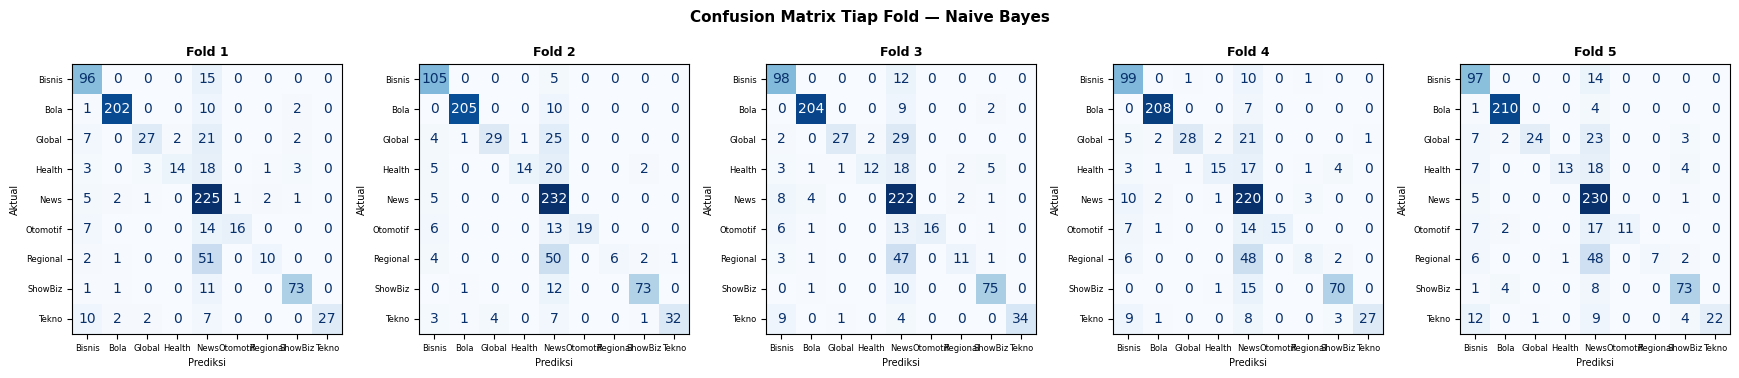

In [ ]:
# Confusion Matrix per Fold (Naive Bayes)
plot_cm_per_fold(nb_fold_cms, CLASS_NAMES, 'Naive Bayes', cmap='Blues')

**Decision Tree**

In [ ]:
# Decision Tree
dt_fold_results, dt_fold_cms, dt_fold_reports = run_kfold_experiment(dt_model, 'Decision Tree', X_raw, y, CLASS_NAMES, skf, TFIDF_PARAMS)

Decision Tree
Fold 1 / 5: Accuracy = 0.7019  Precision = 0.6999  Recall = 0.7019  F1-Score = 0.6998  Waktu = 5.67s
Fold 2 / 5: Accuracy = 0.6815  Precision = 0.6792  Recall = 0.6815  F1-Score = 0.6788  Waktu = 5.33s
Fold 3 / 5: Accuracy = 0.6871  Precision = 0.6843  Recall = 0.6871  F1-Score = 0.6845  Waktu = 5.19s
Fold 4 / 5: Accuracy = 0.6682  Precision = 0.6642  Recall = 0.6682  F1-Score = 0.6636  Waktu = 5.92s
Fold 5 / 5: Accuracy = 0.6826  Precision = 0.6879  Recall = 0.6826  F1-Score = 0.6814  Waktu = 5.01s


In [ ]:
# Classification Report
print('Classification Report Decision Tree')
for i, report in enumerate(dt_fold_reports, 1):
    print(f'\nFold {i} ')
    print(report)

Classification Report Decision Tree

Fold 1 
              precision    recall  f1-score   support

      Bisnis     0.6909    0.6847    0.6878       111
        Bola     0.8559    0.9116    0.8829       215
      Global     0.6066    0.6271    0.6167        59
      Health     0.3191    0.3571    0.3371        42
        News     0.6777    0.6920    0.6848       237
    Otomotif     0.6923    0.7297    0.7105        37
    Regional     0.4902    0.3906    0.4348        64
     ShowBiz     0.7500    0.6977    0.7229        86
       Tekno     0.7750    0.6458    0.7045        48

    accuracy                         0.7019       899
   macro avg     0.6509    0.6374    0.6424       899
weighted avg     0.6999    0.7019    0.6998       899


Fold 2 
              precision    recall  f1-score   support

      Bisnis     0.6154    0.6545    0.6344       110
        Bola     0.9327    0.9023    0.9173       215
      Global     0.4848    0.5333    0.5079        60
      Health     0.2703 

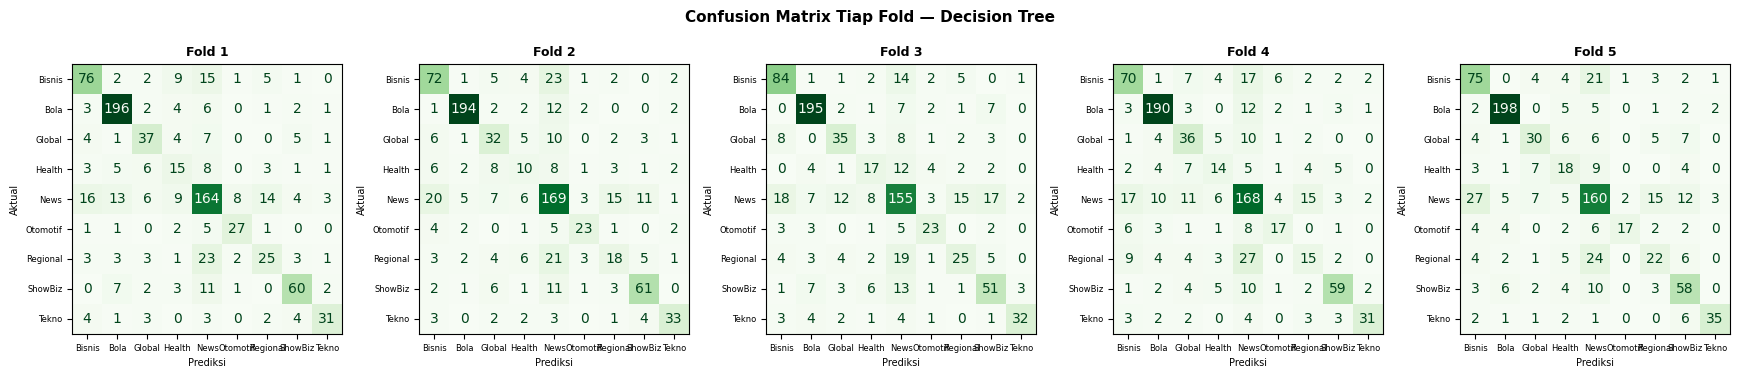

In [ ]:
# Confusion Matrix per Fold (Decision Tree)
plot_cm_per_fold(dt_fold_cms, CLASS_NAMES, 'Decision Tree', cmap='Greens')

**AdaBoost**

In [ ]:
# AdaBoost
ada_fold_results, ada_fold_cms, ada_fold_reports = run_kfold_experiment(ada_model,'AdaBoost', X_raw, y, CLASS_NAMES, skf, TFIDF_PARAMS)

AdaBoost
Fold 1 / 5: Accuracy = 0.7341  Precision = 0.7462  Recall = 0.7341  F1-Score = 0.7291  Waktu = 60.14s
Fold 2 / 5: Accuracy = 0.7249  Precision = 0.7462  Recall = 0.7249  F1-Score = 0.7181  Waktu = 61.73s
Fold 3 / 5: Accuracy = 0.7038  Precision = 0.7341  Recall = 0.7038  F1-Score = 0.7065  Waktu = 60.64s
Fold 4 / 5: Accuracy = 0.7584  Precision = 0.7720  Recall = 0.7584  F1-Score = 0.7586  Waktu = 60.46s
Fold 5 / 5: Accuracy = 0.7227  Precision = 0.7572  Recall = 0.7227  F1-Score = 0.7223  Waktu = 59.53s


In [ ]:
# Classification Report
print('Classification Report AdaBoost')
for i, report in enumerate(ada_fold_reports, 1):
    print(f'\nFold {i} ')
    print(report)

Classification Report AdaBoost

Fold 1 
              precision    recall  f1-score   support

      Bisnis     0.7800    0.7027    0.7393       111
        Bola     0.9754    0.9209    0.9474       215
      Global     0.7333    0.3729    0.4944        59
      Health     0.6000    0.3571    0.4478        42
        News     0.5859    0.8059    0.6785       237
    Otomotif     0.7576    0.6757    0.7143        37
    Regional     0.4490    0.3438    0.3894        64
     ShowBiz     0.7640    0.7907    0.7771        86
       Tekno     0.9318    0.8542    0.8913        48

    accuracy                         0.7341       899
   macro avg     0.7308    0.6471    0.6755       899
weighted avg     0.7462    0.7341    0.7291       899


Fold 2 
              precision    recall  f1-score   support

      Bisnis     0.8000    0.7273    0.7619       110
        Bola     0.9412    0.8930    0.9165       215
      Global     0.7105    0.4500    0.5510        60
      Health     0.6842    0.

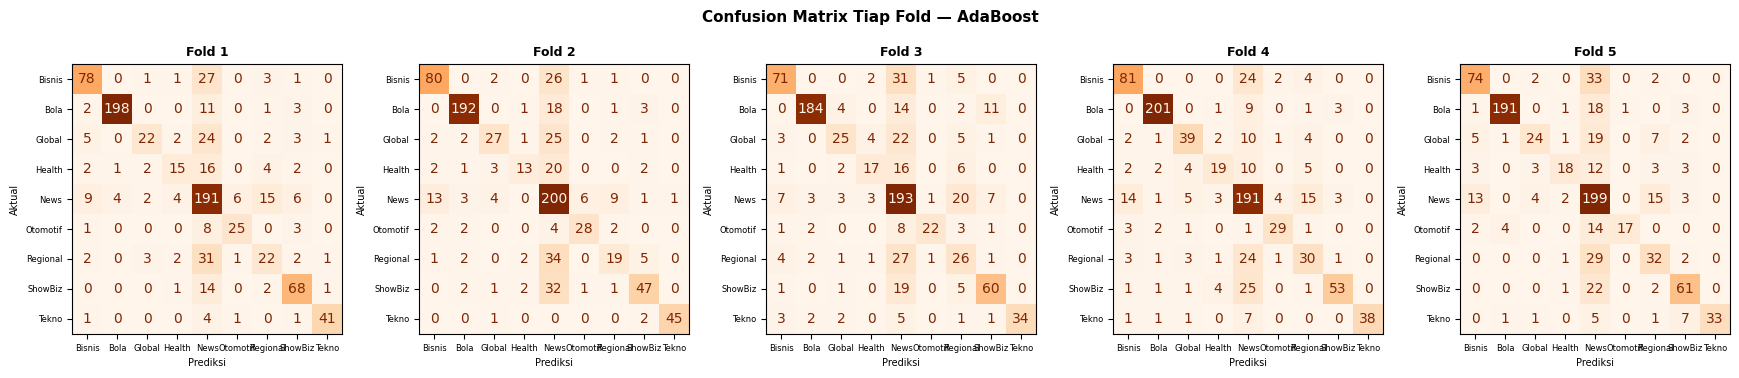

In [ ]:
# Confusion Matrix per Fold (AdaBoost)
plot_cm_per_fold(ada_fold_cms, CLASS_NAMES, 'AdaBoost', cmap='Oranges')

**Hasil Keseluruhan Semua Model**

In [ ]:
nb_df  = print_fold_table(nb_fold_results,  'Naive Bayes')
dt_df  = print_fold_table(dt_fold_results,  'Decision Tree')
ada_df = print_fold_table(ada_fold_results, 'AdaBoost')


Naive Bayes


,fold,accuracy,precision,recall,f1_score,time_sec
0,1,0.7675,0.8092,0.7675,0.7468,2.4779
1,2,0.7962,0.8524,0.7962,0.7712,2.5412
2,3,0.7784,0.8173,0.7784,0.7578,2.5407
3,4,0.7684,0.8000,0.7684,0.7457,3.5447
4,5,0.7650,0.8302,0.7650,0.7324,2.5682
5,Rata-rata,0.7751,0.8218,0.7751,0.7508,2.7346
6,Std Dev,0.0129,0.0204,0.0129,0.0145,0.4541



Decision Tree


,fold,accuracy,precision,recall,f1_score,time_sec
0,1,0.7019,0.6999,0.7019,0.6998,5.6716
1,2,0.6815,0.6792,0.6815,0.6788,5.3274
2,3,0.6871,0.6843,0.6871,0.6845,5.1937
3,4,0.6682,0.6642,0.6682,0.6636,5.9216
4,5,0.6826,0.6879,0.6826,0.6814,5.0091
5,Rata-rata,0.6843,0.6831,0.6843,0.6816,5.4247
6,Std Dev,0.0121,0.0130,0.0121,0.0129,0.3686



AdaBoost


,fold,accuracy,precision,recall,f1_score,time_sec
0,1,0.7341,0.7462,0.7341,0.7291,60.1406
1,2,0.7249,0.7462,0.7249,0.7181,61.7253
2,3,0.7038,0.7341,0.7038,0.7065,60.6429
3,4,0.7584,0.7720,0.7584,0.7586,60.4622
4,5,0.7227,0.7572,0.7227,0.7223,59.5299
5,Rata-rata,0.7288,0.7511,0.7288,0.7269,60.5002
6,Std Dev,0.0199,0.0142,0.0199,0.0195,0.8052


In [ ]:
METRICS = ['accuracy', 'precision', 'recall', 'f1_score', 'time_sec']

summary_rows = []
for name, df_fold in [('Naive Bayes', nb_df), ('Decision Tree', dt_df), ('AdaBoost', ada_df)]:
    avg = df_fold[METRICS].mean()
    std = df_fold[METRICS].std()
    row = {'Model': name}
    for m in METRICS:
        row[f'{m}_mean'] = avg[m]
        row[f'{m}_std']  = std[m]
    summary_rows.append(row)

summary_df = pd.DataFrame(summary_rows)

print('RATA-RATA SEMUA MODEL (K = 5)')
display_cols = ['Model'] + [f'{m}_mean' for m in METRICS]
display(summary_df[display_cols].round(4))

summary_df.to_csv('summary_kfold.csv', index=False)

RATA-RATA SEMUA MODEL (K = 5)


,Model,accuracy_mean,precision_mean,recall_mean,f1_score_mean,time_sec_mean
0,Naive Bayes,0.7751,0.8218,0.7751,0.7508,2.7346
1,Decision Tree,0.6843,0.6831,0.6843,0.6816,5.4247
2,AdaBoost,0.7288,0.7511,0.7288,0.7269,60.5002


**Visualisasi Perbandingan**

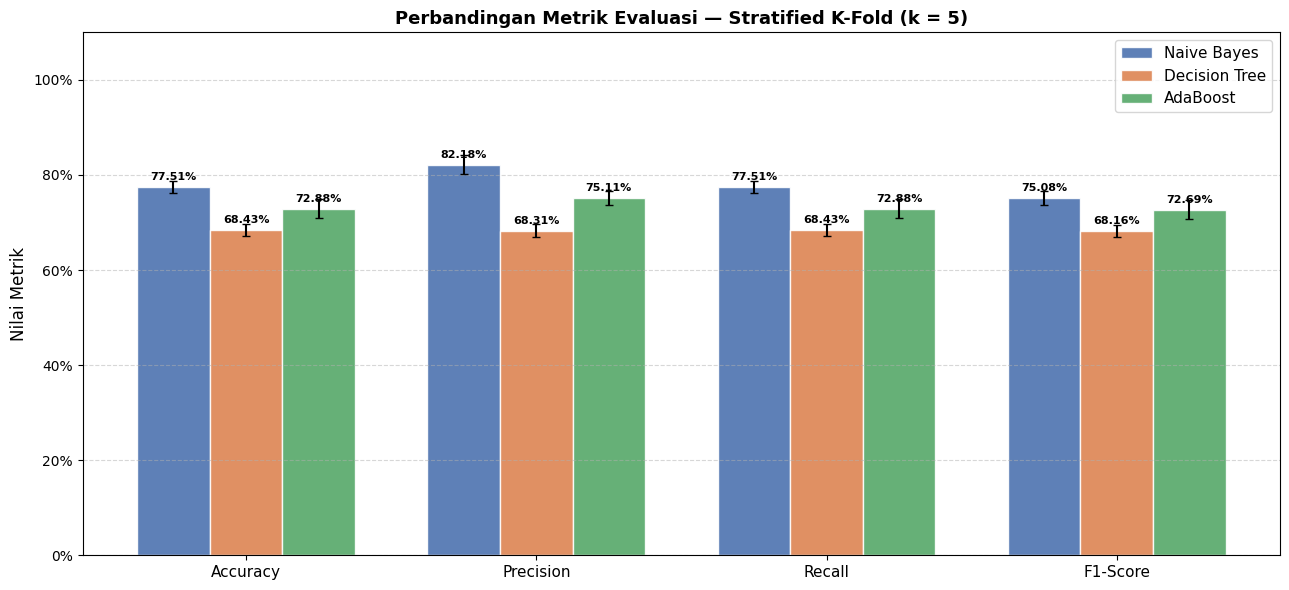

In [ ]:
metric_labels = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
metric_cols   = ['accuracy_mean', 'precision_mean', 'recall_mean', 'f1_score_mean']
std_cols      = ['accuracy_std', 'precision_std', 'recall_std', 'f1_score_std']
model_names   = summary_df['Model'].tolist()
x = np.arange(len(metric_labels))
w = 0.25

fig, ax = plt.subplots(figsize=(13, 6))
for i, (mname, color) in enumerate(MODEL_COLORS.items()):
    row   = summary_df[summary_df['Model'] == mname].iloc[0]
    vals  = [row[c] for c in metric_cols]
    stds  = [row[c] for c in std_cols]
    bars  = ax.bar(x + i*w, vals, w, label=mname, color=color,
                   edgecolor='white', yerr=stds, capsize=3, alpha=0.9)
    for bar, val in zip(bars, vals):
        ax.annotate(f'{val*100:.2f}%',
                    xy=(bar.get_x() + bar.get_width()/2, bar.get_height()),
                    xytext=(0, 5), textcoords='offset points',
                    ha='center', fontsize=8, fontweight='bold')

ax.set_xticks(x + w)
ax.set_xticklabels(metric_labels, fontsize=11)
ax.set_ylim(0, 1.1)
ax.grid(axis='y', linestyle='--', alpha=0.5)
ax.set_ylabel('Nilai Metrik', fontsize=12)
ax.set_title('Perbandingan Metrik Evaluasi — Stratified K-Fold (k = 5)',
             fontsize=13, fontweight='bold')
ax.legend(fontsize=11)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))

plt.tight_layout()
plt.savefig('perbandingan_metrik.png', dpi=150, bbox_inches='tight')
plt.show()

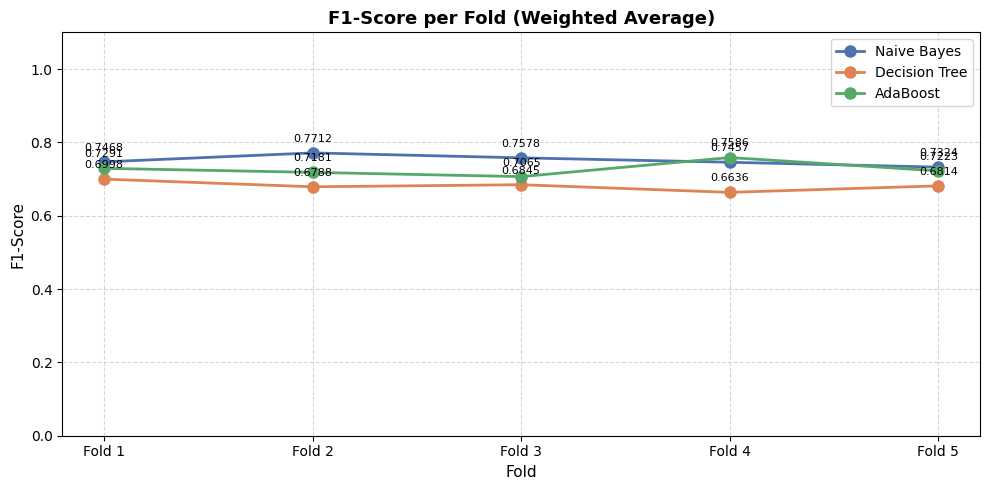

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))
fold_labels = [f'Fold {i}' for i in range(1, K_FOLDS+1)]

for name, df_fold, color in [
        ('Naive Bayes', nb_df, '#4C72B0'),
        ('Decision Tree', dt_df, '#DD8452'),
        ('AdaBoost', ada_df, '#55A868')]:
    ax.plot(fold_labels, df_fold['f1_score'].values,
            marker='o', color=color, lw=2, markersize=8, label=name)
    for j, val in enumerate(df_fold['f1_score'].values):
        ax.annotate(f'{val:.4f}', (fold_labels[j], val),
                    textcoords='offset points', xytext=(0, 8),
                    ha='center', fontsize=8)

ax.set_title('F1-Score per Fold (Weighted Average)', fontsize=13, fontweight='bold')
ax.set_xlabel('Fold', fontsize=11)
ax.set_ylabel('F1-Score', fontsize=11)
ax.grid(axis='y', linestyle='--', alpha=0.5)
ax.grid(axis='x', linestyle='--', alpha=0.5)
ax.legend(fontsize=10)
ax.set_ylim(0, 1.1)
plt.tight_layout()
plt.savefig('f1_per_fold.png', dpi=150, bbox_inches='tight')
plt.show()

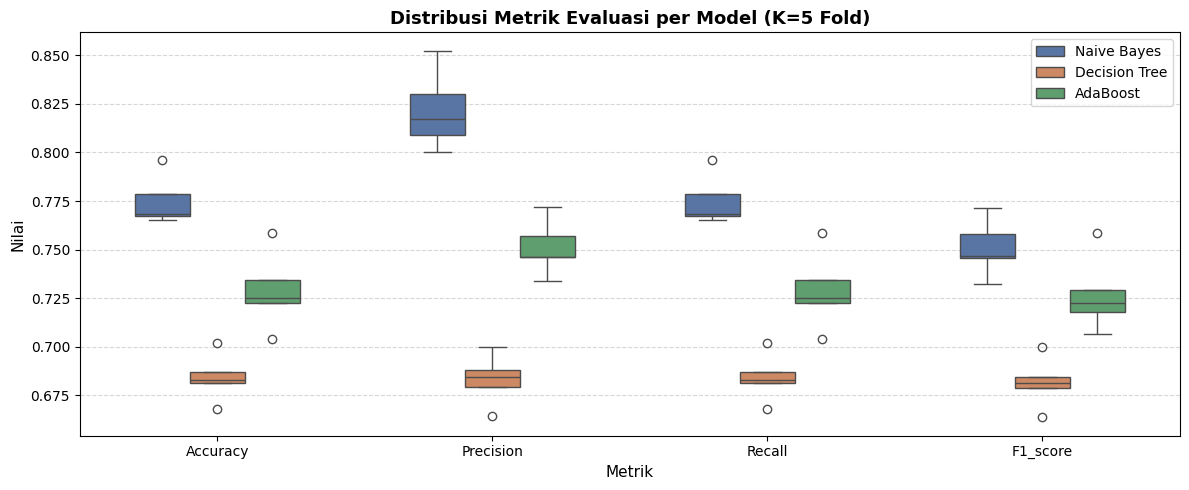

In [ ]:
all_fold_data = []
for name, df_fold in [('Naive Bayes', nb_df), ('Decision Tree', dt_df), ('AdaBoost', ada_df)]:
    for _, row in df_fold.iterrows():
        for met in ['accuracy', 'precision', 'recall', 'f1_score']:
            all_fold_data.append({'Model': name, 'Metrik': met.capitalize(), 'Nilai': row[met]})

box_df = pd.DataFrame(all_fold_data)

fig, ax = plt.subplots(figsize=(12, 5))
palette = {'Naive Bayes': '#4C72B0', 'Decision Tree': '#DD8452', 'AdaBoost': '#55A868'}
sns.boxplot(data=box_df, x='Metrik', y='Nilai', hue='Model',
            palette=palette, ax=ax, width=0.6)
ax.set_title('Distribusi Metrik Evaluasi per Model (K=5 Fold)',
             fontsize=13, fontweight='bold')
ax.set_ylabel('Nilai', fontsize=11)
ax.set_xlabel('Metrik', fontsize=11)
ax.grid(axis='y', linestyle='--', alpha=0.5)
ax.legend(fontsize=10)
plt.tight_layout()
plt.savefig('boxplot_metrik.png', dpi=150, bbox_inches='tight')
plt.show()

**Confusion Matrix**

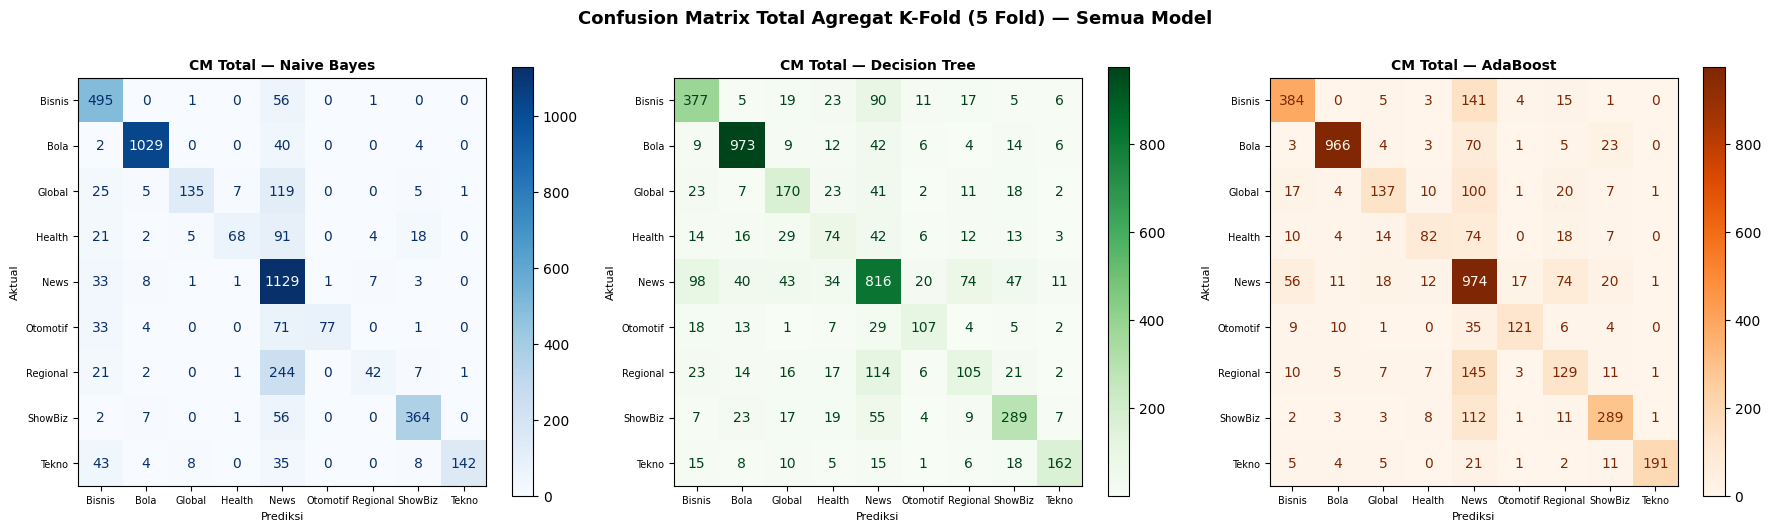

In [ ]:
nb_cm_total  = aggregate_cm(nb_fold_cms)
dt_cm_total  = aggregate_cm(dt_fold_cms)
ada_cm_total = aggregate_cm(ada_fold_cms)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
cmap_dict = {'Naive Bayes': 'Blues', 'Decision Tree': 'Greens', 'AdaBoost': 'Oranges'}
cm_total_dict = {
    'Naive Bayes':   nb_cm_total,
    'Decision Tree': dt_cm_total,
    'AdaBoost':      ada_cm_total
}

for ax, (mname, cm_tot) in zip(axes, cm_total_dict.items()):
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm_tot,
        display_labels=CLASS_NAMES
    )
    disp.plot(values_format='d', cmap=cmap_dict[mname], ax=ax, colorbar=True)
    ax.set_title(f'CM Total — {mname}', fontweight='bold', fontsize=10)
    ax.set_xlabel('Prediksi', fontsize=8)
    ax.set_ylabel('Aktual', fontsize=8)
    ax.tick_params(axis='both', labelsize=7)

fig.suptitle('Confusion Matrix Total Agregat K-Fold (5 Fold) — Semua Model',
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('cm_total_semua_model.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
for mname, cm_tot in cm_total_dict.items():
    tpfpfntn = extract_tpfpfntn_per_class(cm_tot, CLASS_NAMES)
    tpfpfntn['Precision'] = (tpfpfntn['TP'] /
        (tpfpfntn['TP'] + tpfpfntn['FP'] + 1e-9)).round(4)
    tpfpfntn['Recall'] = (tpfpfntn['TP'] /
        (tpfpfntn['TP'] + tpfpfntn['FN'] + 1e-9)).round(4)
    tpfpfntn['F1'] = (2 * tpfpfntn['Precision'] * tpfpfntn['Recall'] /
        (tpfpfntn['Precision'] + tpfpfntn['Recall'] + 1e-9)).round(4)

    print(f'\nTabel TP/FP/FN/TN — {mname}')
    display(tpfpfntn)
    tpfpfntn.to_csv(f'tpfpfntn_{mname.lower().replace(" ","_")}.csv', index=False)


Tabel TP/FP/FN/TN — Naive Bayes


,Kelas,TP,FP,FN,TN,Precision,Recall,F1
0,Bisnis,495,180,58,3758,0.7333,0.8951,0.8062
1,Bola,1029,32,46,3384,0.9698,0.9572,0.9635
2,Global,135,15,162,4179,0.9000,0.4545,0.6040
3,Health,68,10,141,4272,0.8718,0.3254,0.4739
4,News,1129,712,54,2596,0.6133,0.9544,0.7467
5,Otomotif,77,1,109,4304,0.9872,0.4140,0.5834
6,Regional,42,12,276,4161,0.7778,0.1321,0.2258
7,ShowBiz,364,46,66,4015,0.8878,0.8465,0.8667
8,Tekno,142,2,98,4249,0.9861,0.5917,0.7396



Tabel TP/FP/FN/TN — Decision Tree


,Kelas,TP,FP,FN,TN,Precision,Recall,F1
0,Bisnis,377,207,176,3731,0.6455,0.6817,0.6631
1,Bola,973,126,102,3290,0.8854,0.9051,0.8951
2,Global,170,144,127,4050,0.5414,0.5724,0.5565
3,Health,74,140,135,4142,0.3458,0.3541,0.3499
4,News,816,428,367,2880,0.6559,0.6898,0.6724
5,Otomotif,107,56,79,4249,0.6564,0.5753,0.6132
6,Regional,105,137,213,4036,0.4339,0.3302,0.3750
7,ShowBiz,289,141,141,3920,0.6721,0.6721,0.6721
8,Tekno,162,39,78,4212,0.8060,0.6750,0.7347



Tabel TP/FP/FN/TN — AdaBoost


,Kelas,TP,FP,FN,TN,Precision,Recall,F1
0,Bisnis,384,112,169,3826,0.7742,0.6944,0.7321
1,Bola,966,41,109,3375,0.9593,0.8986,0.9280
2,Global,137,57,160,4137,0.7062,0.4613,0.5581
3,Health,82,43,127,4239,0.6560,0.3923,0.4910
4,News,974,698,209,2610,0.5825,0.8233,0.6823
5,Otomotif,121,28,65,4277,0.8121,0.6505,0.7224
6,Regional,129,151,189,4022,0.4607,0.4057,0.4315
7,ShowBiz,289,84,141,3977,0.7748,0.6721,0.7198
8,Tekno,191,4,49,4247,0.9795,0.7958,0.8781


**Kesalahan Klasifikasi Terbanyak**

In [ ]:
print('Analisis Kesalahan Klasifikasi')
for mname, cm_tot in cm_total_dict.items():
    print(f'\n{mname}')
    n = cm_tot.shape[0]
    errors = []
    for i in range(n):
        for j in range(n):
            if i != j and cm_tot[i, j] > 0:
                errors.append({
                    'Aktual':   CLASS_NAMES[i],
                    'Prediksi': CLASS_NAMES[j],
                    'Jumlah':   cm_tot[i, j]
                })
    err_df = pd.DataFrame(errors).sort_values('Jumlah', ascending=False)
    print('Top 5 kesalahan klasifikasi terbanyak:')
    display(err_df.head(5).reset_index(drop=True))

Analisis Kesalahan Klasifikasi

Naive Bayes
Top 5 kesalahan klasifikasi terbanyak:


,Aktual,Prediksi,Jumlah
0,Regional,News,244
1,Global,News,119
2,Health,News,91
3,Otomotif,News,71
4,ShowBiz,News,56



Decision Tree
Top 5 kesalahan klasifikasi terbanyak:


,Aktual,Prediksi,Jumlah
0,Regional,News,114
1,News,Bisnis,98
2,Bisnis,News,90
3,News,Regional,74
4,ShowBiz,News,55



AdaBoost
Top 5 kesalahan klasifikasi terbanyak:


,Aktual,Prediksi,Jumlah
0,Regional,News,145
1,Bisnis,News,141
2,ShowBiz,News,112
3,Global,News,100
4,Health,News,74


**Visualisasi Decision Tree**

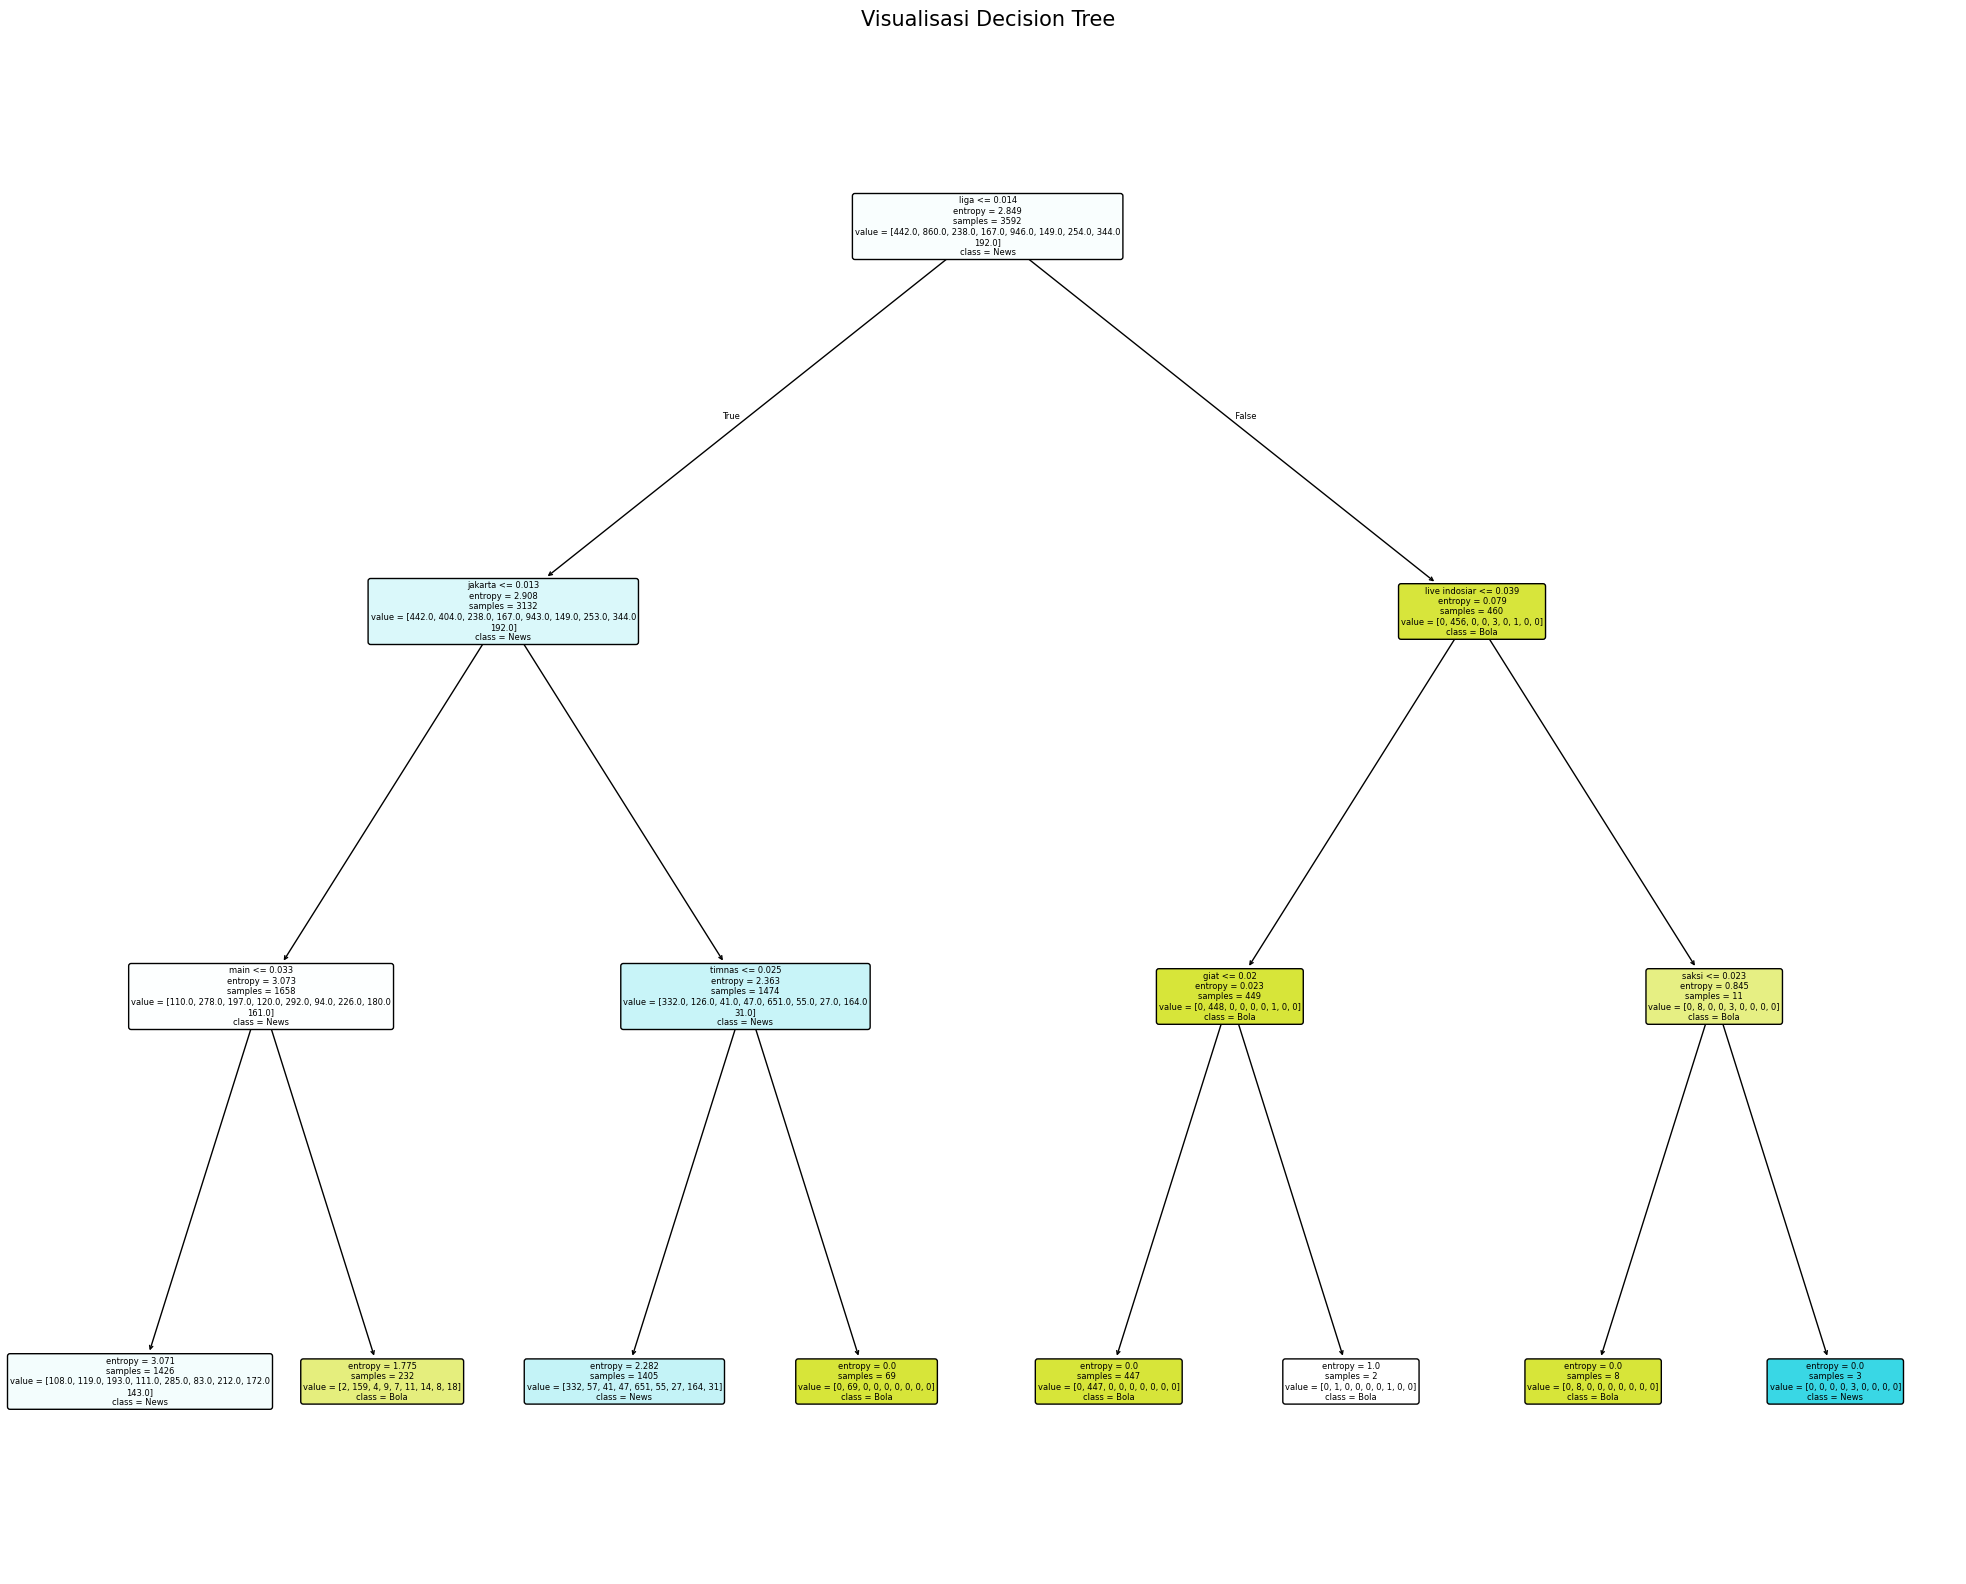

In [ ]:
train_idx, _ = list(skf.split(X_raw, y))[0]
X_train_single_fold_text, y_train_single_fold = X_raw[train_idx], y[train_idx]

X_train_single_fold_transformed = tfidf_vectorizer.transform(X_train_single_fold_text)

dt_visual_model = DecisionTreeClassifier(
    criterion='entropy',
    max_depth=3,
    min_samples_split=dt_model.min_samples_split,
    min_samples_leaf=dt_model.min_samples_leaf,
    random_state=RANDOM_STATE
)
dt_visual_model.fit(X_train_single_fold_transformed, y_train_single_fold)

plt.figure(figsize=(25, 20))
plot_tree(
    dt_visual_model,
    feature_names=tfidf_vectorizer.get_feature_names_out(),
    class_names=CLASS_NAMES,
    filled=True,
    rounded=True,
    fontsize=6
)
plt.title('Visualisasi Decision Tree', fontsize=15)
plt.savefig('decision_tree_vis.png', dpi=200, bbox_inches='tight')
plt.show()

**Visualisasi AdaBoost Base Estimator**

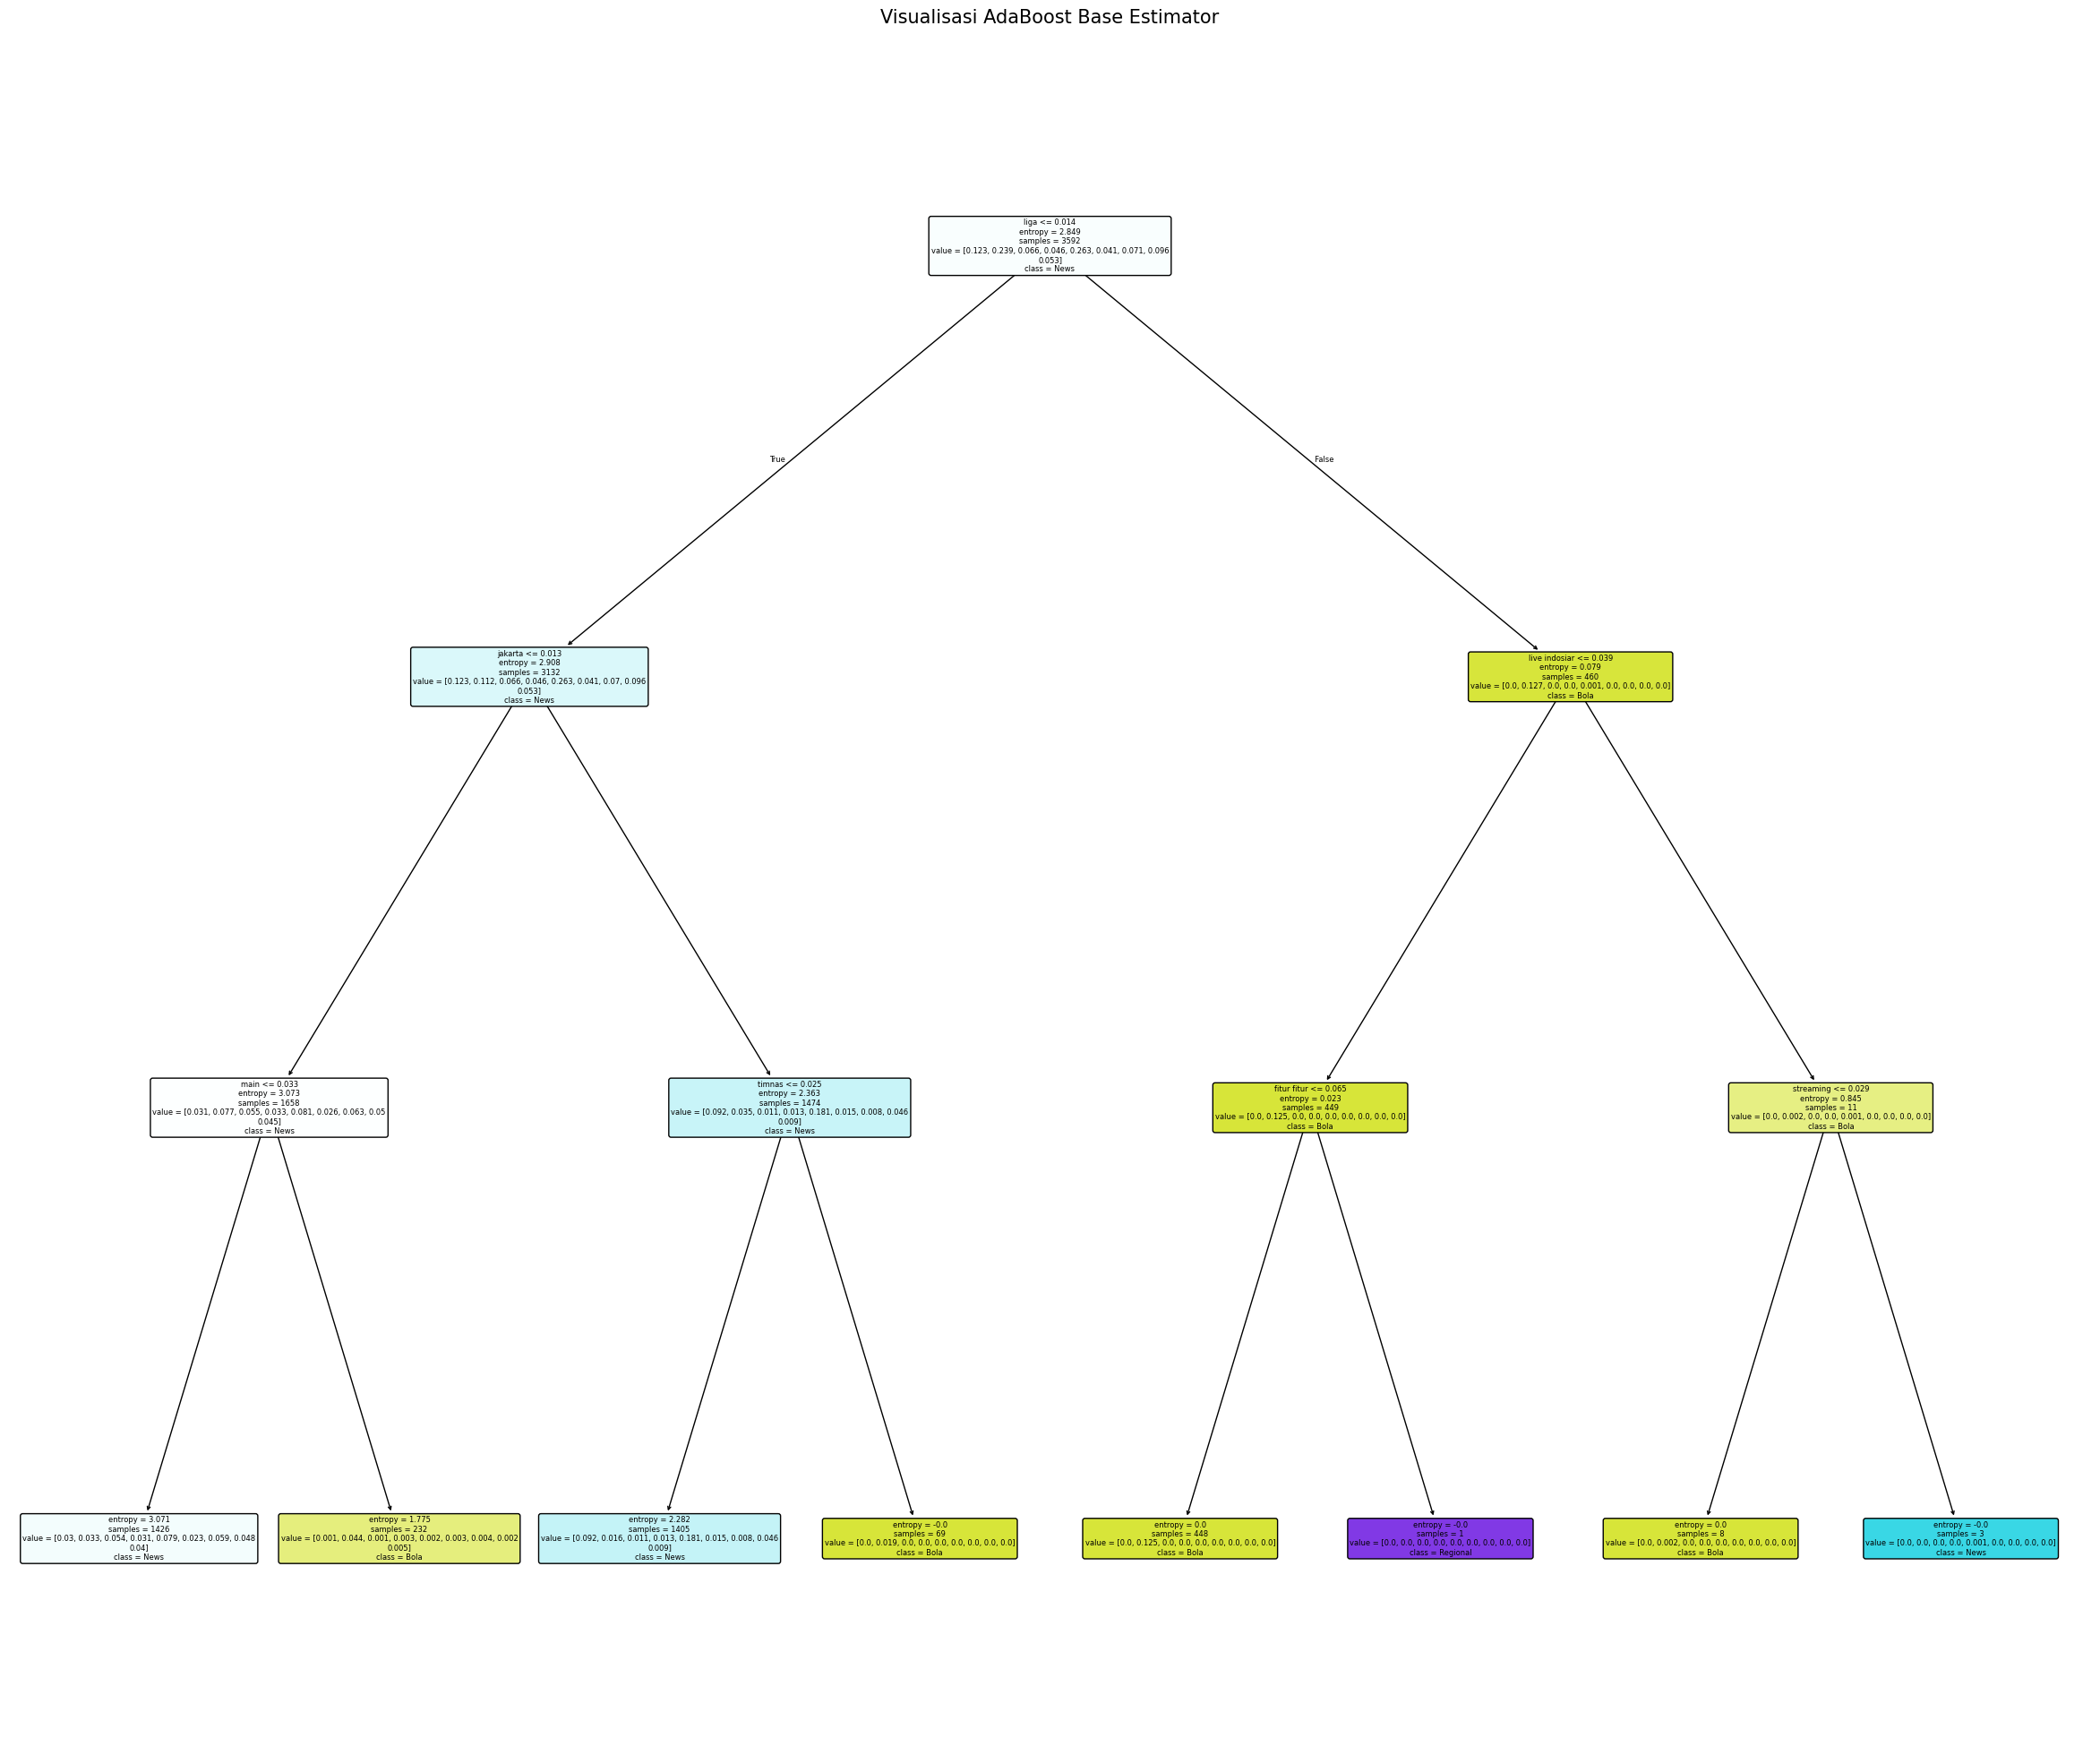

In [ ]:
train_idx_ada, _ = list(skf.split(X_raw, y))[0]
X_train_ada_fold_text, y_train_ada_fold = X_raw[train_idx_ada], y[train_idx_ada]

X_train_ada_fold_transformed = tfidf_vectorizer.transform(X_train_ada_fold_text)

ada_visual_model = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(criterion='entropy', max_depth=3, random_state=RANDOM_STATE),
    n_estimators=100,
    learning_rate=1.0,
    algorithm='SAMME',
    random_state=RANDOM_STATE
)
ada_visual_model.fit(X_train_ada_fold_transformed, y_train_ada_fold)

plt.figure(figsize=(30, 25))
plot_tree(
    ada_visual_model.estimators_[0],
    feature_names=tfidf_vectorizer.get_feature_names_out(),
    class_names=CLASS_NAMES,
    filled=True,
    rounded=True,
    fontsize=6
)
plt.title('Visualisasi AdaBoost Base Estimator', fontsize=15)
plt.savefig('adaboost_base_estimator_vis.png', dpi=200, bbox_inches='tight')
plt.show()

**Model Terbaik**

In [ ]:
ranking_df = summary_df[['Model', 'accuracy_mean', 'precision_mean', 'recall_mean', 'f1_score_mean', 'time_sec_mean']].copy()
ranking_df.columns = ['Model', 'Accuracy', 'Precision', 'Recall', 'F1-Score', 'Waktu (s)']
ranking_df = ranking_df.sort_values('F1-Score', ascending=False).reset_index(drop=True)
print('HASIL KESELURUHAN ALGORITMA')
display(ranking_df.round(4))
ranking_df.to_csv('top_algoritma.csv')

HASIL KESELURUHAN ALGORITMA


,Model,Accuracy,Precision,Recall,F1-Score,Waktu (s)
0,Naive Bayes,0.7751,0.8218,0.7751,0.7508,2.7346
1,AdaBoost,0.7288,0.7511,0.7288,0.7269,60.5002
2,Decision Tree,0.6843,0.6831,0.6843,0.6816,5.4247


In [ ]:
best_model_name = ranking_df.iloc[0]['Model']
best_model      = MODELS[best_model_name]

In [ ]:
print(f'Model terbaik : {best_model_name}')
print(f'Dengan Accuracy rata-rata: {ranking_df.iloc[0]["Accuracy"]:.4f}')

Model terbaik : Naive Bayes
Dengan Accuracy rata-rata: 0.7751


In [ ]:
print(f'Model terbaik : {best_model_name}')
print(f'Dengan F1-Score rata-rata: {ranking_df.iloc[0]["F1-Score"]:.4f}')

Model terbaik : Naive Bayes
Dengan F1-Score rata-rata: 0.7508


In [ ]:
# Melatih ulang pipeline terbaik
final_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(**TFIDF_PARAMS)),
    ('clf',   clone(best_model))
])

t0 = time.time()
final_pipeline.fit(X_raw, y)
print(f'Selesai dalam {time.time()-t0:.2f}s')

Selesai dalam 3.08s


**Contoh Simulasi Prediksi**

In [ ]:
# Prediksi Berita Baru
def predict_news(text: str) -> dict:
    # Preprocessing
    clean = preprocess_text(text)
    if clean.strip() == '':
        return {'kategori_prediksi': 'TIDAK DAPAT DIKLASIFIKASI',
                'confidence_score': 0.0, 'probability_all': {}}

    # Prediksi
    pred_encoded = final_pipeline.predict([clean])[0]
    pred_label   = le.inverse_transform([pred_encoded])[0]

    prob_dict = {}
    confidence = 1.0
    if hasattr(final_pipeline.named_steps['clf'], 'predict_proba'):
        proba      = final_pipeline.predict_proba([clean])[0]
        confidence = float(proba.max())
        prob_dict  = dict(zip(le.classes_, proba.round(4)))

    return {
        'kategori_prediksi': pred_label,
        'confidence_score':  round(float(confidence), 4),
        'probability_all':   prob_dict
    }

In [ ]:
test_news = [
    {
        'id': 1,
        'teks': ('Timnas Indonesia berhasil meraih kemenangan '
                 'telak 3-0 atas Malaysia dalam laga persahabatan '
                 'di Stadion Gelora Bung Karno. Gol dicetak oleh '
                 'Egy Maulana Vikri dan Witan Sulaeman.'),
        'label_sebenarnya': 'Bola'
    },
    {
        'id': 2,
        'teks': ('Bank Indonesia memutuskan mempertahankan suku bunga '
                 'acuan BI Rate di level 5,75 persen pada Rapat Dewan '
                 'Gubernur bulan ini guna menjaga stabilitas nilai tukar '
                 'rupiah dan mengendalikan inflasi.'),
        'label_sebenarnya': 'Bisnis'
    },
    {
        'id': 3,
        'teks': ('Kementerian Kesehatan mengimbau masyarakat untuk segera '
                 'melakukan vaksinasi influenza terutama bagi kelompok '
                 'rentan seperti lansia dan anak-anak di bawah lima tahun '
                 'menjelang musim hujan.'),
        'label_sebenarnya': 'Health'
    },
    {
        'id': 4,
        'teks': ('Samsung merilis smartphone terbaru seri Galaxy S25 '
                 'dengan chipset Snapdragon 8 Elite, layar AMOLED 120Hz, '
                 'dan kapasitas baterai 5000 mAh dengan pengisian cepat 65W.'),
        'label_sebenarnya': 'Tekno'
    },
    {
        'id': 5,
        'teks': ('DPR RI mengesahkan Rancangan Undang-Undang Pemilu '
                 'yang mengatur mekanisme pemilihan presiden, DPR, DPRD, '
                 'dan DPD secara serentak pada tahun 2029.'),
        'label_sebenarnya': 'News'
    },
    {
        'id': 6,
        'teks': ('Pemerintah mengumumkan kebijakan baru terkait pajak dan investasi yang bertujuan mendorong pertumbuhan ekonomi nasional dan menarik investor asing.'),
        'label_sebenarnya': 'Bisnis'
    },
]

In [ ]:
print(f'Pengujian Prediksi Data Baru dengan Model {best_model_name} ')

inference_rows = []
for item in test_news:
    result = predict_news(item['teks'])
    correct = '✓' if result['kategori_prediksi'] == item['label_sebenarnya'] else '✗'

    print(f"\n[{item['id']}] Input: {item['teks'][:80]}...")
    print(f"     Kategori Aktual  : {item['label_sebenarnya']}")
    print(f"     Prediksi         : {result['kategori_prediksi']}  {correct}")
    print(f"     Confidence Score : {result['confidence_score']:.4f}")
    if result['probability_all']:
        top3 = sorted(result['probability_all'].items(), key=lambda x: x[1], reverse=True)[:3]
        print(f"     Top 3 Probabilitas: " + '  |  '.join([f" {k} : {v:.4f}" for k, v in top3]))

    inference_rows.append({
        'id': item['id'],
        'aktual': item['label_sebenarnya'],
        'prediksi': result['kategori_prediksi'],
        'confidence': result['confidence_score'],
        'benar': result['kategori_prediksi'] == item['label_sebenarnya']
    })

inf_df = pd.DataFrame(inference_rows)
acc_inf = inf_df['benar'].mean()

Pengujian Prediksi Data Baru dengan Model Naive Bayes 

[1] Input: Timnas Indonesia berhasil meraih kemenangan telak 3-0 atas Malaysia dalam laga p...
     Kategori Aktual  : Bola
     Prediksi         : Bola  ✓
     Confidence Score : 0.9946
     Top 3 Probabilitas:  Bola : 0.9946  |   ShowBiz : 0.0012  |   News : 0.0010

[2] Input: Bank Indonesia memutuskan mempertahankan suku bunga acuan BI Rate di level 5,75 ...
     Kategori Aktual  : Bisnis
     Prediksi         : Bisnis  ✓
     Confidence Score : 0.9349
     Top 3 Probabilitas:  Bisnis : 0.9349  |   News : 0.0262  |   Regional : 0.0094

[3] Input: Kementerian Kesehatan mengimbau masyarakat untuk segera melakukan vaksinasi infl...
     Kategori Aktual  : Health
     Prediksi         : News  ✗
     Confidence Score : 0.3778
     Top 3 Probabilitas:  News : 0.3778  |   Health : 0.1774  |   Regional : 0.1498

[4] Input: Samsung merilis smartphone terbaru seri Galaxy S25 dengan chipset Snapdragon 8 E...
     Kategori Aktual  : Tekno


In [ ]:
print(f'Akurasi pada 6 contoh: {acc_inf*100:.1f}% ({inf_df["benar"].sum()}/{len(inf_df)})')

Akurasi pada 6 contoh: 83.3% (5/6)


In [ ]:
display(inf_df)

,id,aktual,prediksi,confidence,benar
0,1,Bola,Bola,0.9946,True
1,2,Bisnis,Bisnis,0.9349,True
2,3,Health,News,0.3778,False
3,4,Tekno,Tekno,0.9365,True
4,5,News,News,0.9752,True
5,6,Bisnis,Bisnis,0.9174,True


**Kesimpulan**

In [ ]:
print('Tabel Keseluruhan')

avg_row = ranking_df[['Accuracy', 'Precision', 'Recall', 'F1-Score', 'Waktu (s)']].mean().to_frame().T
avg_row['Model'] = 'Rata-rata'

avg_row = avg_row[ranking_df.columns]

display_df = pd.concat([ranking_df, avg_row], ignore_index=True)
display(display_df.round(4))

best   = ranking_df.iloc[0]
second = ranking_df.iloc[1]
worst  = ranking_df.iloc[-1]

print()
print(f'MODEL TERBAIK: {best["Model"]}')
print(f'Accuracy     : {best["Accuracy"]:.4f}')
print(f'Precision    : {best["Precision"]:.4f}')
print(f'Recall       : {best["Recall"]:.4f}')
print(f'F1-Score     : {best["F1-Score"]:.4f}')
print(f'Waktu latih  : {best["Waktu (s)"]:.4f}s per fold')

Tabel Keseluruhan


,Model,Accuracy,Precision,Recall,F1-Score,Waktu (s)
0,Naive Bayes,0.7751,0.8218,0.7751,0.7508,2.7346
1,AdaBoost,0.7288,0.7511,0.7288,0.7269,60.5002
2,Decision Tree,0.6843,0.6831,0.6843,0.6816,5.4247
3,Rata-rata,0.7294,0.7520,0.7294,0.7198,22.8865



MODEL TERBAIK: Naive Bayes
Accuracy     : 0.7751
Precision    : 0.8218
Recall       : 0.7751
F1-Score     : 0.7508
Waktu latih  : 2.7346s per fold


In [ ]:
print(f'Dataset     : Liputan6 ({len(df_filtered):,} artikel, {N_CLASSES} kategori)')
print(f'Fitur       : TF-IDF (max_features=10000, ngram_range=(1,2))')
print(f'Evaluasi    : Stratified K-Fold, k={K_FOLDS}')

Dataset     : Liputan6 (4,491 artikel, 9 kategori)
Fitur       : TF-IDF (max_features=10000, ngram_range=(1,2))
Evaluasi    : Stratified K-Fold, k=5
